# Préambule: Import des librairies

In [1]:
import sys
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

Python: 3.11.17
Platform: macOS-27.0.1-arm64-arm-64bit
NumPy: 2.4.6
Pandas: 3.1.1
Scikit-learn: 1.9.1


# 1. Collecte des données
On utilise un dataset issu de réservations de 2 hôtels situés au Portugal:

https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand

## 1.1. Chargement des données
Chargement du dataset dans un dataframe Pandas et copie dans un dataframe de travail

In [2]:
df_original = pd.read_csv("input/hotel_bookings.csv")
df = df_original.copy()
print("Lignes, colonnes:",df.shape)

Lignes, colonnes: (119390, 32)


## 1.2. Aperçu des données

In [3]:
print("\n--- Aperçu des données ---")
display(df.head())

print("\nStatistiques descriptives numériques:")
display(df[df.select_dtypes(include=['number']).columns].describe(include='all'))

print("\nStatistiques descriptives catégorielles:")
display(df[df.select_dtypes(exclude=['number']).columns].describe(include='all'))

print("\nTypes des colonnes:")
df.info()



--- Aperçu des données ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



Statistiques descriptives numériques:


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000



Statistiques descriptives catégorielles:


,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
count,119390,119390,119390,118902,119390,119390,119390,119390,119390,119390,119390,119390
unique,2,12,5,177,8,5,10,12,3,4,3,926
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out,2015-10-21
freq,79330,13877,92310,48590,56477,97870,85994,74053,104641,89613,75166,1461



Types des colonnes:
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal  

## 1.3. Nomenclature des colonnes
Description du contenu des colonnes selon la fiche Kaggle:

hotel: One of the hotels is a resort hotel and the other is a city hotel.
is_canceled lead_time: Value indicating if the booking was canceled (1) or not (0).
arrival_date_year: Year of arrival date.
arrival_date_month: Month of arrival date with 12 categories: “January” to “December”.
arrival_date_week_number: Week number of the arrival date.
arrival_date_day_of_month: Day of the month of the arrival date.
stays_in_weekend_nights: Number of weekend nights (Saturday or Sunday) the guest stayed or booked to stay at the hotel.
stays_in_week_nights: Number of week nights (Monday to Friday) the guest stayed.
adults: Number of adults
children: Number of Childern
babies: Number of Babies
meal: BB – Bed & Breakfast
country: Country of origin.
market_segment: Market segment designation. In categories, the term “TA” means “Travel Agents” and “TO” means “Tour Operators”
distribution_channel: Booking distribution channel. The term “TA” means “Travel Agents” and “TO” means “Tour Operators”
is_repeated_guest: Value indicating if the booking name was from a repeated guest (1) or not (0)
previous_cancellations: Number of previous bookings that were cancelled by the customer prior to the current booking
previous_bookings_not_canceled: Number of previous bookings not cancelled by the customer prior to the current booking
reserved_room_type: Code of room type reserved. Code is presented instead of designation for anonymity reasons.
assigned_room_type: Code for the type of room assigned to the booking. Sometimes the assigned room type differs from the reserved room type due to hotel operation reasons (e.g. overbooking) or by customer request. Code is presented instead of designation for anonymity reasons
booking_changes: Number of changes/amendments made to the booking.
deposit_type: No Deposit – no deposit was made; Non Refund – a deposit was made in the value of the total stay cost; Refundable – a deposit was made with a value under the total cost of stay.
agent: ID of the travel agency that made the booking
company: ID of the company/entity that made the booking or responsible for paying the booking. ID is presented instead of designation for anonymity reasons
days_in_waiting_list: Number of days the booking was in the waiting list before it was confirmed to the customer
customer_type: Group – when the booking is associated to a group; Transient – when the booking is not part of a group or contract, and is not associated to other transient booking; Transient-party – when the booking is transient, but is associated to at least other transient booking
adr: Average Daily Rate (Calculated by dividing the sum of all lodging transactions by the total number of staying nights)
required_car_parking_spaces: Number of car parking spaces required by the customer
total_of_special_requests: Number of special requests made by the customer (e.g. twin bed or high floor)
reservation_status: Check-Out – customer has checked in but already departed; No-Show – customer did not check-in and did inform the hotel of the reason why
reservation_status_date: Date at which the last status was set. This variable can be used in conjunction with the ReservationStatus to understand when was the booking canceled or when did the customer checked-out of the hotel


# 3. Exploration des données


## 3.1. Corrélation a priori des colonnes numériques avec l'annulation
On cherche à avoir un aperçu des caractéristiques qui ont la plus forte corrélation avec l'annulation

In [4]:
correlation = df[df.select_dtypes(include=['number']).columns].corr()['is_canceled'].abs().sort_values(ascending = False)
correlation

is_canceled                       1.000000
lead_time                         0.293123
total_of_special_requests         0.234658
required_car_parking_spaces       0.195498
booking_changes                   0.144381
previous_cancellations            0.110133
is_repeated_guest                 0.084793
agent                             0.083114
adults                            0.060017
previous_bookings_not_canceled    0.057358
days_in_waiting_list              0.054186
adr                               0.047557
babies                            0.032491
stays_in_week_nights              0.024765
company                           0.020642
arrival_date_year                 0.016660
arrival_date_week_number          0.008148
arrival_date_day_of_month         0.006130
children                          0.005048
stays_in_weekend_nights           0.001791
Name: is_canceled, dtype: float64

## 3.2. Valeurs uniques des colonnes catégorielles
Quels sont les domaines de définition des caracétristiques catégorielles ?

In [4]:
for col in df.select_dtypes(exclude=['number']).columns:
    print(f"{col}: \n{df[col].unique()}\n")

hotel: 
<StringArray>
['Resort Hotel', 'City Hotel']
Length: 2, dtype: str

arrival_date_month: 
<StringArray>
[     'July',    'August', 'September',   'October',  'November',  'December',
   'January',  'February',     'March',     'April',       'May',      'June']
Length: 12, dtype: str

meal: 
<StringArray>
['BB', 'FB', 'HB', 'SC', 'Undefined']
Length: 5, dtype: str

country: 
<StringArray>
['PRT', 'GBR', 'USA', 'ESP', 'IRL', 'FRA',   nan, 'ROU', 'NOR', 'OMN',
 ...
 'ATA', 'GTM', 'ASM', 'MRT', 'NCL', 'KIR', 'SDN', 'ATF', 'SLE', 'LAO']
Length: 178, dtype: str

market_segment: 
<StringArray>
[       'Direct',     'Corporate',     'Online TA', 'Offline TA/TO',
 'Complementary',        'Groups',     'Undefined',      'Aviation']
Length: 8, dtype: str

distribution_channel: 
<StringArray>
['Direct', 'Corporate', 'TA/TO', 'Undefined', 'GDS']
Length: 5, dtype: str

reserved_room_type: 
<StringArray>
['C', 'A', 'D', 'E', 'G', 'F', 'H', 'L', 'P', 'B']
Length: 10, dtype: str

assigned_room_

# 2. Nettoyage des données
## 2.1. Valeurs manquantes
Il y a 4 colonnes avec des valeurs manquantes:
- children: Nombre d'enfants
- country: Pays d'origine de la réservation
- agent: Identifiant de l'agence de voyage ayant effectué la réservation
- company: Identifiant de l'entreprise ayant effectué ou payé la réservation, si séjour professionel


In [5]:
print("Valeurs manquantes par colonne:")
display(df.isnull().sum())


Valeurs manquantes par colonne:


hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

### Traitement des valeurs manquantes
- Il y a peu de valeurs manquantes (4) dans la colonne "children", on peut remplacer ces valeurs par 0
- En cas d'absence de valeur dans la colonne "country", on la remplace arbitrairement par "UNKNOWN"
- En cas d'absence d'identifiant d'agence de voyage, on considère que la réservation a été faite en direct, on remplace par la valeur 0 qui n'est pas utilisée (on a min=0 pour la colonne 'agent')
- En cas d'absence d'identifiant d'entreprise, on considère que la réservation a été faite par un particulier, on remplace par la valeur 0 qui n'est pas utilisée (on a min=0 pour la colonne 'agent')

In [6]:
df['children'] = df['children'].fillna(0)
df['country'] = df['country'].fillna('UNKNOWN')
df['agent'] = df['agent'].fillna(0)
df['company'] = df['company'].fillna(0)

print("Vérification des manquants après traitement:")
display(df.isnull().sum())


Vérification des manquants après traitement:


hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
customer_type                     0
adr                         

## 2.2. Valeurs hors-norme (outliers)

### 3.2.1. Suppression des valeurs impossibles
- Lorsqu'il n'y a aucun adulte
- Lorsqu'il y a plus de 4 enfants
- Lorsqu'il ya plus de 2 bébés
- Lorsque le prix est négatif
- Lorsque le prix par nuit est anormalement élevé: prix moyen et médiane proches de 100 avec un écart type de 50, le maximum est de 5400, on supprime les prix au dessus de 2000


In [7]:
outliers = pd.DataFrame({
    'Aucun adulte': df['adults'] <= 0,
    'Plus de 4 enfants': df['children'] > 4,
    'Plus de 2 bébés': df['babies'] > 2,
    'Prix négatif (adr < 0)': df['adr'] < 0,
    'Prix par nuit trop élevé': df['adr'] > 2000,
})
print(outliers.sum().to_string(), '\n')
a_supprimer = outliers.any(axis=1)
df = df[~a_supprimer].copy()
print(f'Suppressions: {a_supprimer.sum()} lignes. {len(df):,} réservations restantes.')


Aucun adulte                403
Plus de 4 enfants             1
Plus de 2 bébés               2
Prix négatif (adr < 0)        1
Prix par nuit trop élevé      1 

Suppressions: 408 lignes. 118,982 réservations restantes.


## 2.3. Duplicates ?

## 3.3. Features engeneering

### 3.3.1. Regroupement de valeurs
- Selon la data card du dataset, la clonne "meal" a 2 valuers qui ont la même signification: Undefined/SC – no meal package, on remplace donc "Undefined" par "SC"

In [8]:
df['meal'] = df['meal'].replace('Undefined', 'SC') 


In [10]:
#del df_copy["company"]

# Grouper réservations antérieures
#df['total_previous_bookings'] = df['previous_cancellations'] + df['previous_bookings_not_canceled']

# Etiquettage deposit_type
#df['deposit_type'] = df['deposit_type'].replace({'No Deposit':0,
#                                                 'Non Refund':1,
#                                                 'Refundable':2
#						 })


## Visualisations

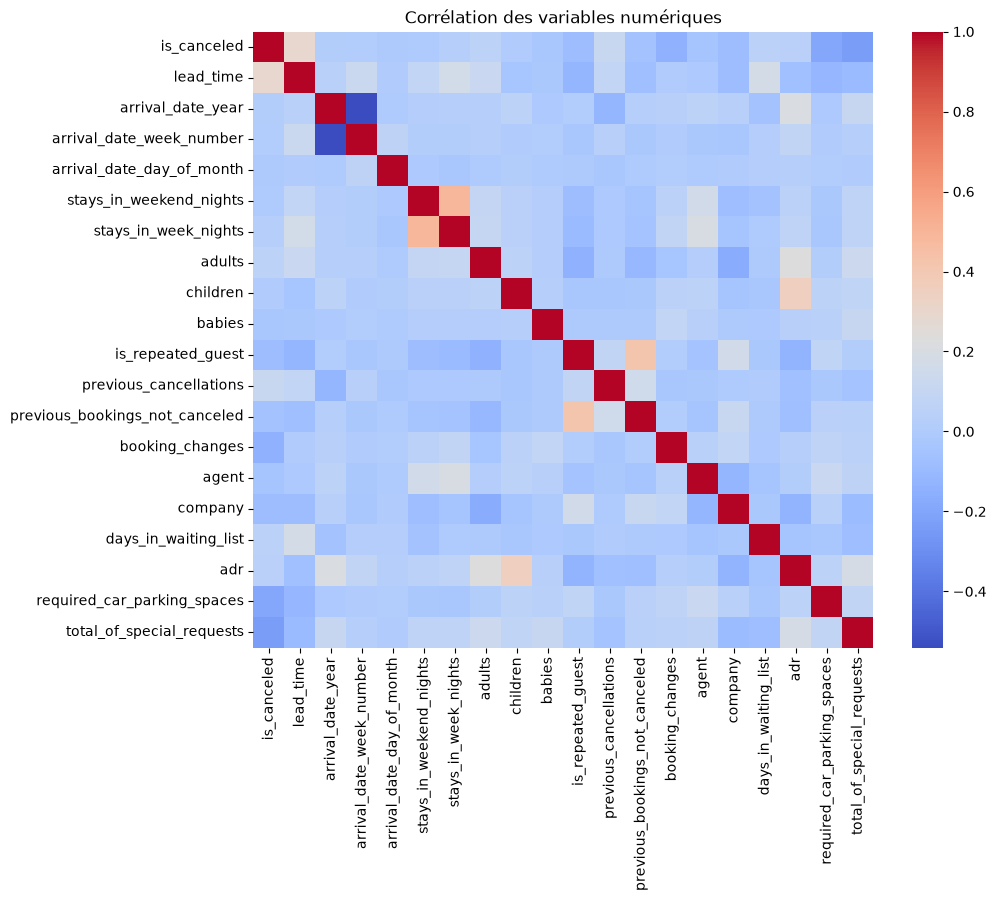

is_canceled                       1.000000
lead_time                         0.293001
total_of_special_requests         0.235273
required_car_parking_spaces       0.195867
booking_changes                   0.144888
previous_cancellations            0.110224
is_repeated_guest                 0.083772
company                           0.083677
adults                            0.058881
previous_bookings_not_canceled    0.057406
days_in_waiting_list              0.054358
adr                               0.047546
agent                             0.046794
babies                            0.034217
stays_in_week_nights              0.025321
arrival_date_year                 0.016467
arrival_date_week_number          0.008321
arrival_date_day_of_month         0.005899
children                          0.004570
stays_in_weekend_nights           0.001391
Name: is_canceled, dtype: float64


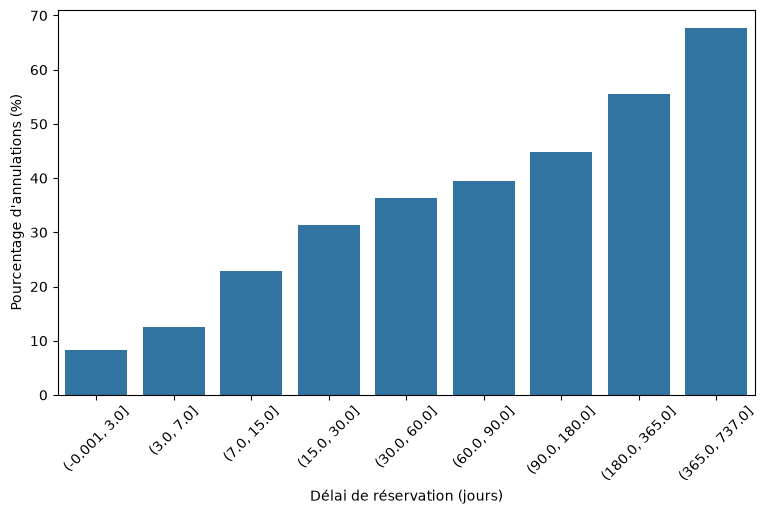

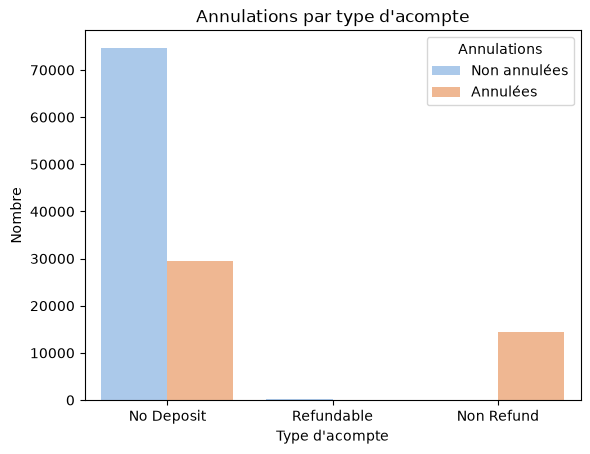

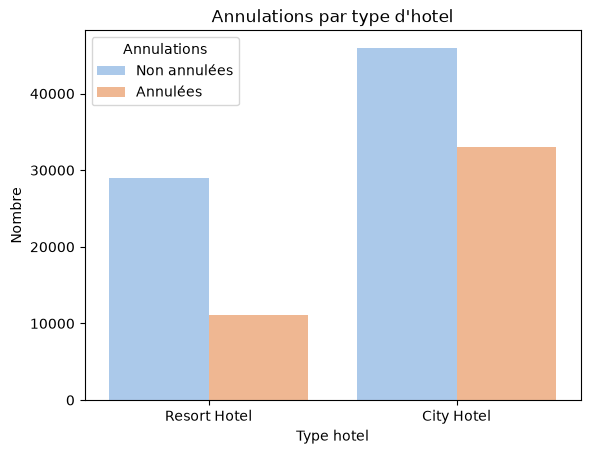

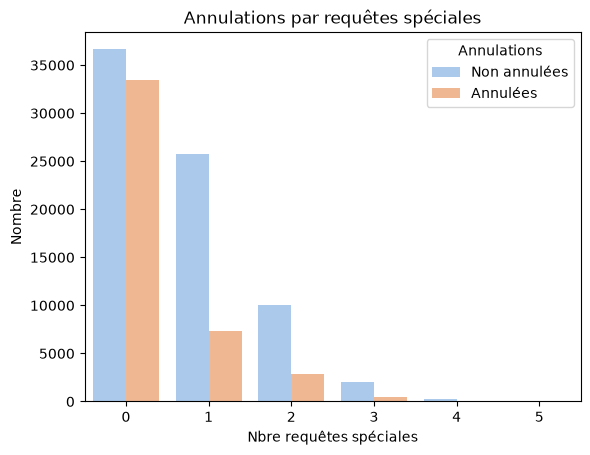

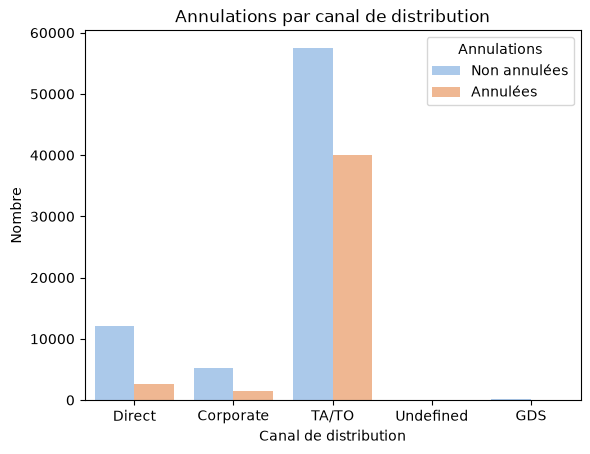

In [9]:
num_cols = df.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), cmap='coolwarm', annot=False)
plt.title("Corrélation des variables numériques")
plt.show()

correlation = df[df.select_dtypes(include=['number']).columns].corr()['is_canceled'].abs().sort_values(ascending = False)
print(correlation)

# Découpage de lead_time en intervalles
bins = [0, 3, 7, 15, 30, 60, 90, 180, 365, df["lead_time"].max()]
df_lead = df.copy()
df_lead["lead_time_bin"] = pd.cut(df_lead["lead_time"], bins=bins, include_lowest=True)

# Pourcentage d'annulation par intervalle
taux = (df_lead.groupby("lead_time_bin", observed=True)["is_canceled"]
          .mean()
          .mul(100)
          .reset_index())

plt.figure(figsize=(9, 5))
sns.barplot(data=taux, x="lead_time_bin", y="is_canceled")
plt.ylabel("Pourcentage d'annulations (%)")
plt.xlabel("Délai de réservation (jours)")
plt.xticks(rotation=45)
plt.show()

# Courbe lissée sans intervalles
#sns.lineplot(
#    data=df_lead.assign(lead_time_bin=pd.cut(df_lead["lead_time"], bins=40)
#                     .apply(lambda x: x.mid).astype(float)),
#    x="lead_time_bin", y="is_canceled", errorbar=None
#)
#plt.show()

sns.countplot(x="deposit_type", hue="is_canceled", data=df, palette="pastel")
plt.title("Annulations par type d'acompte")
plt.xlabel("Type d'acompte")
plt.ylabel("Nombre")
plt.legend(title="Annulations", labels=["Non annulées", "Annulées"])
plt.show()

sns.countplot(x="hotel", hue="is_canceled", data=df, palette="pastel")
plt.title("Annulations par type d'hotel")
plt.xlabel("Type hotel")
plt.ylabel("Nombre")
plt.legend(title="Annulations", labels=["Non annulées", "Annulées"])
plt.show()

sns.countplot(x="total_of_special_requests", hue="is_canceled", data=df, palette="pastel")
plt.title("Annulations par requêtes spéciales")
plt.xlabel("Nbre requêtes spéciales")
plt.ylabel("Nombre")
plt.legend(title="Annulations", labels=["Non annulées", "Annulées"])
plt.show()

sns.countplot(x="distribution_channel", hue="is_canceled", data=df, palette="pastel")
plt.title("Annulations par canal de distribution")
plt.xlabel("Canal de distribution")
plt.ylabel("Nombre")
plt.legend(title="Annulations", labels=["Non annulées", "Annulées"])
plt.show()



# Séparation caractéristiques (X) et cible (y)

In [10]:
print("\nSéparation des variables explicatives et de la cible...")

# dropping columns that are not useful
useless_col = ['days_in_waiting_list', 'arrival_date_year', 'arrival_date_year', 'assigned_room_type', 'booking_changes',
               'reservation_status', 'country', 'days_in_waiting_list', 'reservation_status_date']
df.drop(useless_col, axis = 1, inplace = True)

# Convert 'arrival_date_month' to numerical values
months = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
df['arrival_date_month'] = df['arrival_date_month'].apply(lambda x: months.index(x) + 1)

# One-hot encode the specified columns
one_hot_cols = ['hotel', 'meal', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type']
df = pd.get_dummies(df, columns=one_hot_cols, drop_first=True)

df.info()

#X = df_copy.drop('is_canceled', axis=1)
#y = df_copy['is_canceled']

#X = df_copy[['lead_time','shop_id','week_day','month']].copy()
#numeric_cols = ['sales_partial']
#y = df_copy['is_canceled'].copy()
#
#X.head()


Séparation des variables explicatives et de la cible...
<class 'pandas.DataFrame'>
Index: 118982 entries, 0 to 119389
Data columns (total 46 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   is_canceled                     118982 non-null  int64  
 1   lead_time                       118982 non-null  int64  
 2   arrival_date_month              118982 non-null  int64  
 3   arrival_date_week_number        118982 non-null  int64  
 4   arrival_date_day_of_month       118982 non-null  int64  
 5   stays_in_weekend_nights         118982 non-null  int64  
 6   stays_in_week_nights            118982 non-null  int64  
 7   adults                          118982 non-null  int64  
 8   children                        118982 non-null  float64
 9   babies                          118982 non-null  int64  
 10  is_repeated_guest               118982 non-null  int64  
 11  previous_cancellations          11898

/var/folders/dj/k05clp5x37qcn2hq678_5gd80000gn/T/ipykernel_6585/2406275380.py:6: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(useless_col, axis = 1, inplace = True)


In [11]:
# Define the features (X) and the output labels (y)
X = df.drop('is_canceled', axis=1)
y = df['is_canceled'] 

In [12]:
X.dtypes

lead_time                           int64
arrival_date_month                  int64
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
agent                             float64
company                           float64
adr                               float64
required_car_parking_spaces         int64
total_of_special_requests           int64
hotel_Resort Hotel                   bool
meal_FB                              bool
meal_HB                              bool
meal_SC                              bool
market_segment_Complementary         bool
market_segment_Corporate             bool
market_segment_Direct             

In [13]:
print(f"X shape: {X.shape}, y shape: {y.shape}")

X shape: (118982, 45), y shape: (118982,)


In [14]:
# Splitting data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)

In [15]:
# Regression logistique
lr = LogisticRegression()
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

acc_lr = accuracy_score(y_test, y_pred_lr)
conf = confusion_matrix(y_test, y_pred_lr)
clf_report = classification_report(y_test, y_pred_lr)

print(f"Accuracy Score of Logistic Regression is : {acc_lr}")
print(f"Confusion Matrix : \n{conf}")
print(f"Classification Report : \n{clf_report}")

Accuracy Score of Logistic Regression is : 0.7858553599193175
Confusion Matrix : 
[[13237  1737]
 [ 3359  5464]]
Classification Report : 
              precision    recall  f1-score   support

           0       0.80      0.88      0.84     14974
           1       0.76      0.62      0.68      8823

    accuracy                           0.79     23797
   macro avg       0.78      0.75      0.76     23797
weighted avg       0.78      0.79      0.78     23797



/Users/joel/developpements/Alyra AI/Projet/stay_prediction/machine_learning/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [16]:
# Random forest tree

rd_clf = RandomForestClassifier()
rd_clf.fit(X_train, y_train)

y_pred_rd_clf = rd_clf.predict(X_test)

acc_rd_clf = accuracy_score(y_test, y_pred_rd_clf)
conf = confusion_matrix(y_test, y_pred_rd_clf)
clf_report = classification_report(y_test, y_pred_rd_clf)

print(f"Accuracy Score of Random Forest is : {acc_rd_clf}")
print(f"Confusion Matrix : \n{conf}")
print(f"Classification Report : \n{clf_report}")

Accuracy Score of Random Forest is : 0.868933058788923
Confusion Matrix : 
[[13965  1009]
 [ 2110  6713]]
Classification Report : 
              precision    recall  f1-score   support

           0       0.87      0.93      0.90     14974
           1       0.87      0.76      0.81      8823

    accuracy                           0.87     23797
   macro avg       0.87      0.85      0.86     23797
weighted avg       0.87      0.87      0.87     23797



In [17]:
# XGboostong
xgb = XGBClassifier(booster = 'gbtree', learning_rate = 0.1, max_depth = 5, n_estimators = 180)
xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)

acc_xgb = accuracy_score(y_test, y_pred_xgb)
conf = confusion_matrix(y_test, y_pred_xgb)
clf_report = classification_report(y_test, y_pred_xgb)

print(f"Accuracy Score of Ada Boost Classifier is : {acc_xgb}")
print(f"Confusion Matrix : \n{conf}")
print(f"Classification Report : \n{clf_report}")

NameError: name 'XGBClassifier' is not defined

# Construction Modèle 1

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, precision_score, recall_score, accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

start_rows = len(df)

# --- 1. Fill missing values where the meaning is clear ---
#df['children'] = df['children'].fillna(0).astype(int)     # 4 rows: assume no children
#df['country'] = df['country'].fillna('Unknown')            # keep these bookings, label the country
df['has_agent'] = df['agent'].notna().astype(int)          # 1 = booked through a travel agent
df['has_company'] = df['company'].notna().astype(int)      # 1 = a company booked/paid

# --- 2. Merge labels that mean the same thing ---
#df['meal'] = df['meal'].replace('Undefined', 'SC')         # both mean "no meal package"

# --- 3. Remove impossible rows ---
#guests = df['adults'] + df['children'] + df['babies']
#problems = pd.DataFrame({
#    'No guests at all': guests == 0,
#    'Negative price (adr < 0)': df['adr'] < 0,
#    'Price over 1,000 per night': df['adr'] > 1000,
#})
#print(problems.sum().to_string(), '\n')
#bad = problems.any(axis=1)
#df = df[~bad].copy()
#print(f'Removed {bad.sum()} rows ({bad.sum() / start_rows:.2%}). {len(df):,} bookings left.')


# --- 4. Add helpful columns ---
df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-' + df['arrival_date_month'] + '-'
    + df['arrival_date_day_of_month'].astype(str), format='%Y-%B-%d')


NUMERIC = ['lead_time', 'arrival_date_week_number', 'stays_in_weekend_nights', 'stays_in_week_nights',
           'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations',
           'previous_bookings_not_canceled', 'days_in_waiting_list', 'adr', 'total_of_special_requests',
           'has_agent', 'has_company']
CATEGORICAL = ['hotel', 'arrival_date_month', 'meal', 'market_segment', 'distribution_channel',
               'reserved_room_type', 'deposit_type', 'customer_type']
FEATURES = NUMERIC + CATEGORICAL

train = df[df['arrival_date'] < '2017-01-01']
test = df[df['arrival_date'] >= '2017-01-01']
print(f'Train: {len(train):,} bookings (Jul 2015 - Dec 2016), {train.is_canceled.mean():.0%} cancelled')
print(f'Test:  {len(test):,} bookings (Jan - Aug 2017), {test.is_canceled.mean():.0%} cancelled')


def make_model(estimator, numeric=NUMERIC, categorical=CATEGORICAL):
    """Pipeline = prepare the columns, then fit the model. Same steps for train and test, no mix-ups."""
    prep = ColumnTransformer([
        ('num', StandardScaler(), numeric),                                     # put numbers on the same scale
        ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=50,
                              sparse_output=False), categorical),               # text -> 0/1 columns
    ])
    return Pipeline([('prep', prep), ('model', estimator)])


models = {
    'Logistic regression': make_model(LogisticRegression(max_iter=3000)),
    'Gradient boosting': make_model(HistGradientBoostingClassifier(random_state=42)),
}
scores = {}
for name, model in models.items():
    model.fit(train[FEATURES], train['is_canceled'])
    scores[name] = model.predict_proba(test[FEATURES])[:, 1]
    print(f'{name:20s} AUC on 2017 = {roc_auc_score(test.is_canceled, scores[name]):.3f}')

No guests at all              180
Negative price (adr < 0)        1
Price over 1,000 per night      1 

Removed 182 rows (0.15%). 119,208 bookings left.
Train: 78,589 bookings (Jul 2015 - Dec 2016), 36% cancelled
Test:  40,619 bookings (Jan - Aug 2017), 39% cancelled
Logistic regression  AUC on 2017 = 0.807
Gradient boosting    AUC on 2017 = 0.825


In [70]:
k=0
for ligne in test.itertuples():
	#print(f"Index= {ligne.Index}, is_canceled={ligne.is_canceled}, hotel={ligne.hotel}")
	data_test = test.iloc[[k]].copy()
	#print(data_test)
	if ligne.is_canceled == 1 :
		prediction = models['Logistic regression'].predict(data_test)
		if prediction[0] == 1 :
			break
	k = k+1
	#if k>20:
	#	break
	#display(data_test.iloc[[0]])
	#print(i, ": is_canceled=", data_test.iloc[[0]]['is_canceled'].item)
	#if ligne.is_canceled == 1 :
	#	print("is_canceled a index ", ligne.Index)
	#	data_test = test.loc[[ligne.Index]].copy()
	#	break

print(f"k={k}")
display(data_test)
#prediction = models['Logistic regression'].predict(data_test)
print(f"Prédiction: {prediction[0]}\n")
display(prediction)



k=64


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,has_agent,has_company,arrival_date
9839,Resort Hotel,1,322,2017,January,2,10,16,40,2,...,0,Transient,25.5,0,0,Canceled,2016-10-31,1,0,2017-01-10


Prédiction: 1



array([1])

# Construction modèle 2

In [13]:
NUMERIC = ['lead_time', 'arrival_date_week_number', 'stays_in_weekend_nights', 'stays_in_week_nights',
           'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations',
           'previous_bookings_not_canceled', 'days_in_waiting_list', 'adr', 'total_of_special_requests',
           'has_agent', 'has_company']
CATEGORICAL = ['hotel', 'meal', 'market_segment', 'distribution_channel',
               'reserved_room_type', 'deposit_type', 'customer_type']
FEATURES = NUMERIC + CATEGORICAL

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (95512, 32) Test: (23878, 32)


In [15]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer()),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessing = ColumnTransformer([
    ("num", numeric_pipeline, NUMERIC),
    ("cat", categorical_pipeline, CATEGORICAL)
])

In [16]:
def create_features(df):
    
    df = df.copy()
    
    # taille de la famille
    df["family_size"] = df["adults"] + df["children"]+ df["babies"]
    
    # personne seule ou non
    df["is_alone"] = (df["family_size"] == 1).astype(int)
    
    
    return df

pipe_logreg = Pipeline([
    
    ("features", FunctionTransformer(create_features)),
    
    ("preprocess", preprocessing),
    
    ("model", LogisticRegression(max_iter=5000))
])

In [17]:
# séparation jeu de validation pour tuning hyperparamètres
print("Before split:", X_train.shape)

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=42
)

print("After split:", X_train_sub.shape, "Validation:", X_val.shape)

Before split: (95512, 32)
After split: (76409, 32) Validation: (19103, 32)


In [18]:
# Validation croisée en 5 folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [19]:
grid_logreg = GridSearchCV(
    
    estimator=pipe_logreg,
    
    param_grid={
        "model__C": [0.01, 0.1, 1, 10],
        "preprocess__num__imputer__strategy": ["mean", "median"],
    },
    
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

grid_logreg.fit(X_val, y_val)

print("Best params:", grid_logreg.best_params_)
print("Best CV score:", grid_logreg.best_score_)

ValueError: 
All the 40 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
17 fits failed with the following error:
Traceback (most recent call last):
  File "/Users/joel/developpements/Alyra AI/Projet Bloc 5/.venv/lib/python3.11/site-packages/sklearn/utils/_indexing.py", line 411, in _get_column_indices
    return [column_names.index(col) for col in selected_columns]
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/joel/developpements/Alyra AI/Projet Bloc 5/.venv/lib/python3.11/site-packages/sklearn/utils/_indexing.py", line 411, in <listcomp>
    return [column_names.index(col) for col in selected_columns]
            ^^^^^^^^^^^^^^^^^^^^^^^
ValueError: 'has_agent' is not in list

The above exception was the direct cause of the following exception:

Trace